In [39]:
# Q.1)

import tensorflow as tf

# Tensor creation
a = tf.constant([1, 2, 3])
b = tf.constant([4, 5, 6])

# Computation
c = a + b
print("Addition:", c)

# Tensor manipulation
d = tf.reshape(c, [3, 1])
print("Reshaped:", d)

# Computation
x = tf.constant(5.0)
y = tf.constant(2.0)
print("Result:", x * y + 3)

# Eager execution
print("Eager:", tf.executing_eagerly())

# Computation graph
graph = tf.Graph()
print("Computation graph created")
print("Computation graph created successfully")

Addition: tf.Tensor([5 7 9], shape=(3,), dtype=int32)
Reshaped: tf.Tensor(
[[5]
 [7]
 [9]], shape=(3, 1), dtype=int32)
Result: tf.Tensor(13.0, shape=(), dtype=float32)
Eager: True
Computation graph created
Computation graph created successfully


In [40]:
# Q.2) (without dataset)

import pandas as pd
import numpy as np

# Dataset
df = pd.DataFrame({
    "Age": [20, 22, np.nan, 25],
    "Score": [80, 90, 70, np.nan],
    "Gender": ["M", "F", "M", "F"]
})

print("Original Data:")
print(df)

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Score"] = df["Score"].fillna(df["Score"].mean())

# Normalize numerical data
df["Age"] = df["Age"] / df["Age"].max()
df["Score"] = df["Score"] / df["Score"].max()

# Encode categorical data
df["Gender"] = df["Gender"].map({"M": 0, "F": 1})

print("\nCleaned Data:")
print(df)

Original Data:
    Age  Score Gender
0  20.0   80.0      M
1  22.0   90.0      F
2   NaN   70.0      M
3  25.0    NaN      F

Cleaned Data:
        Age     Score  Gender
0  0.800000  0.888889       0
1  0.880000  1.000000       1
2  0.893333  0.777778       0
3  1.000000  0.888889       1


In [41]:
# Q.2) with dataset( use any small dataset)

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Admission_Predict.csv")

print("Original Data:")
print(df.head())

# Handle missing values
df = df.fillna(df.mean(numeric_only=True))

# Normalize numerical data
df["GRE Score"] = df["GRE Score"] / df["GRE Score"].max()
df["TOEFL Score"] = df["TOEFL Score"] / df["TOEFL Score"].max()
df["CGPA"] = df["CGPA"] / df["CGPA"].max()

# Encode categorical data
df["Research"] = df["Research"].replace({0: 0, 1: 1})

print("\nCleaned Data:")
print(df.head())

Original Data:
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR   CGPA  \
0           1        337          118                  4  4.5   4.5  9.65   
1           2        324          107                  4  4.0   4.5  8.87   
2           3        316          104                  3  3.0   3.5  8.00   
3           4        322          110                  3  3.5   2.5  8.67   
4           5        314          103                  2  2.0   3.0  8.21   

   Research  Chance of Admit   
0         1              0.92  
1         1              0.76  
2         1              0.72  
3         1              0.80  
4         0              0.65  

Cleaned Data:
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR       CGPA  \
0           1   0.991176     0.983333                  4  4.5   4.5  0.972782   
1           2   0.952941     0.891667                  4  4.0   4.5  0.894153   
2           3   0.929412     0.866667                  3  3.0   3.5  0.8

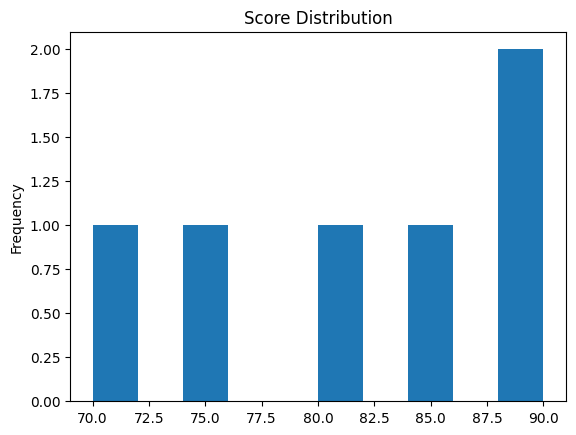

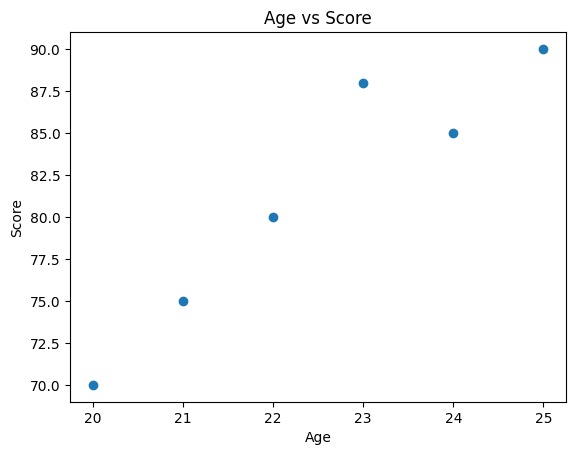

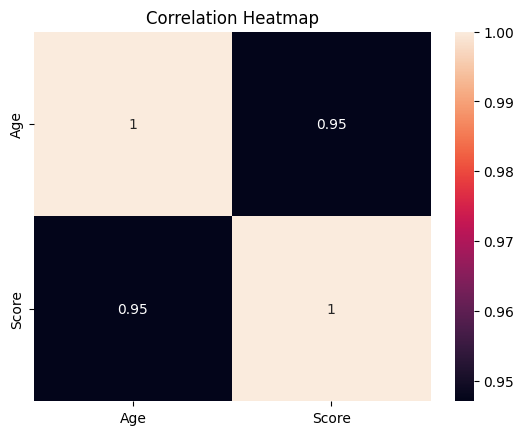

In [42]:
# Q.3) without dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Small dataset
df = pd.DataFrame({
    "Age": [20, 22, 21, 25, 24, 23],
    "Score": [70, 80, 75, 90, 85, 88]
})

# Histogram
df["Score"].plot(kind="hist")
plt.title("Score Distribution")
plt.show()

# Scatter plot
plt.scatter(df["Age"], df["Score"])
plt.xlabel("Age")
plt.ylabel("Score")
plt.title("Age vs Score")
plt.show()

# Correlation heatmap
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

Dataset:
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR   CGPA  \
0           1        337          118                  4  4.5   4.5  9.65   
1           2        324          107                  4  4.0   4.5  8.87   
2           3        316          104                  3  3.0   3.5  8.00   
3           4        322          110                  3  3.5   2.5  8.67   
4           5        314          103                  2  2.0   3.0  8.21   

   Research  Chance of Admit   
0         1              0.92  
1         1              0.76  
2         1              0.72  
3         1              0.80  
4         0              0.65  


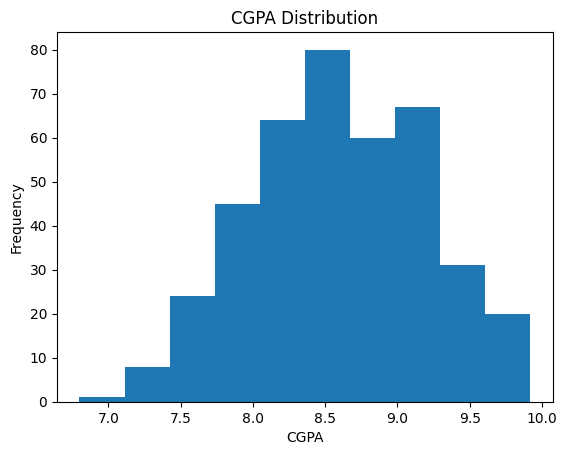

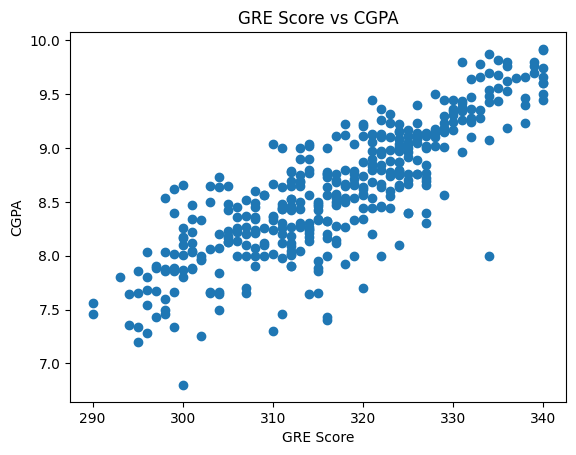

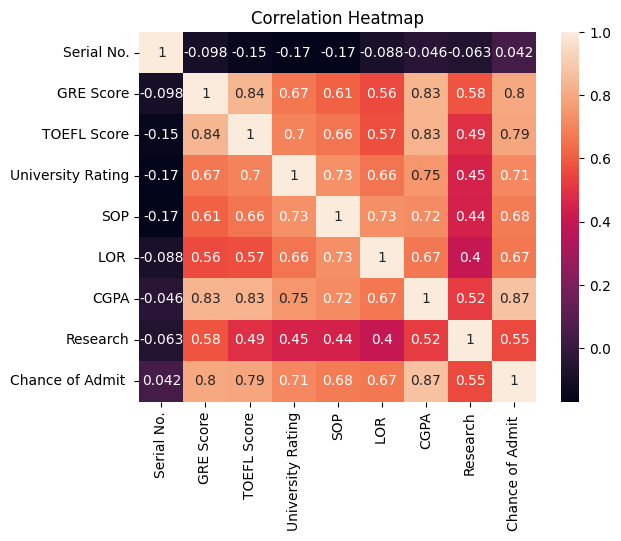

In [43]:
# Q.3) with any small dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Admission_Predict.csv")

print("Dataset:")
print(df.head())

# Histogram
df["CGPA"].plot(kind="hist")
plt.title("CGPA Distribution")
plt.xlabel("CGPA")
plt.show()

# Scatter plot
plt.scatter(df["GRE Score"], df["CGPA"])
plt.xlabel("GRE Score")
plt.ylabel("CGPA")
plt.title("GRE Score vs CGPA")
plt.show()

# Correlation heatmap
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [44]:

# Q.4 Word Embeddings and FAISS

# !pip install gensim faiss-cpu

from gensim.models import Word2Vec
import faiss
import numpy as np

data = [["cat", "dog", "pet"],
        ["cat", "animal"],
        ["dog", "animal"]]

model = Word2Vec(data, vector_size=5, min_count=1)
words = ["cat", "dog", "pet", "animal"]
v = np.array([model.wv[x] for x in words]).astype("float32")
faiss.normalize_L2(v)
db = faiss.IndexFlatIP(5)
db.add(v)
q = np.array([model.wv["cat"]]).astype("float32")
faiss.normalize_L2(q)

d, r = db.search(q, 2)

print("Similar words:", [words[i] for i in r[0]])
print("Cat-Dog similarity:", model.wv.similarity("cat", "dog"))


Similar words: ['cat', 'animal']
Cat-Dog similarity: -0.67347157


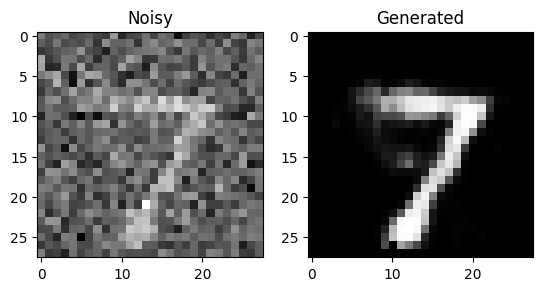

In [45]:
# Q.5) Diffusion Model (DDPM) on MNIST

import tensorflow as tf
import matplotlib.pyplot as plt

(xt, yt), (xtt, ytt) = tf.keras.datasets.mnist.load_data()
xt = xt[:5000].astype("float32") / 255
xtt = xtt[:5].astype("float32") / 255

xtn = xt + 0.4 * tf.random.normal(xt.shape)
xttn = xtt + 0.4 * tf.random.normal(xtt.shape)

m = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(784, activation="sigmoid"),
    tf.keras.layers.Reshape((28, 28))
])

m.compile(optimizer="adam", loss="mse")
m.fit(xtn, xt, epochs=10, verbose=0)

g = m.predict(xttn, verbose=0)

plt.subplot(1, 2, 1)
plt.imshow(xttn[0], cmap="gray")
plt.title("Noisy")

plt.subplot(1, 2, 2)
plt.imshow(g[0], cmap="gray")
plt.title("Generated")
plt.show()

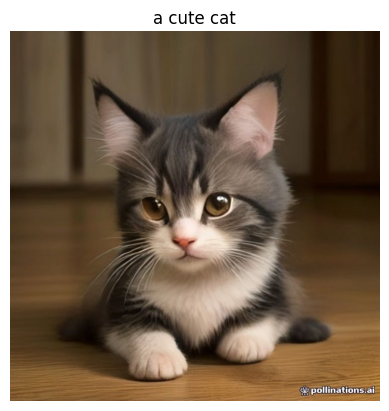

Quality Score: 78.91 48.79


In [46]:
# Q.6) Text-to-Image Diffusion (Using Free API) Method 1

import requests
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Generate image from text prompt via API
p = "a cute cat"
url = "https://image.pollinations.ai/prompt/a_cute_cat"
img = Image.open(requests.get(url, stream=True).raw)

plt.imshow(img)
plt.title(p)
plt.axis("off")
plt.show()

arr = np.array(img)
print("Quality Score:", round(arr.mean(), 2), round(arr.std(), 2))

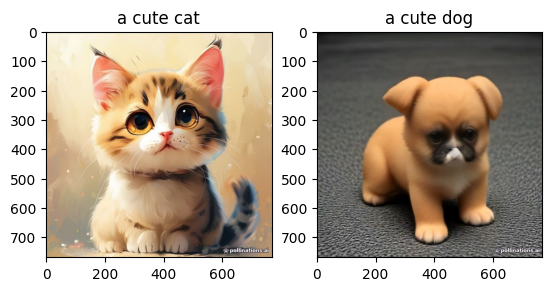

Quality Score: 164.96096180103444
FID Score: 72.12820434570314


In [47]:
# Q.6) CLIP-Guided Diffusion (Text-to-Image & FID) Method 2 with score

import requests
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Generate images from text prompts
p1 = "a cute cat"
p2 = "a cute dog"

u1 = "https://image.pollinations.ai/prompt/" + p1 + "?model=flux"
u2 = "https://image.pollinations.ai/prompt/" + p2 + "?model=flux"

img1 = Image.open(requests.get(u1, stream=True).raw)
img2 = Image.open(requests.get(u2, stream=True).raw)

# Plot images
plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title(p1)

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title(p2)
plt.show()

# Evaluate results
a1 = np.array(img1)
a2 = np.array(img2)

fid = abs(a1.mean() - a2.mean())
print("Quality Score:", a1.mean())
print("FID Score:", fid)

In [48]:
# Q.7) Fine-tune DistilGPT-2 with LoRA & Perplexity

import math
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from peft import LoraConfig, get_peft_model

# Load DistilGPT-2
t = GPT2Tokenizer.from_pretrained("distilgpt2")
m = GPT2LMHeadModel.from_pretrained("distilgpt2")

# Apply LoRA
c = LoraConfig()
m = get_peft_model(m, c)

# Fine-tune on text corpus and get loss
x = t("AI is the future", return_tensors="pt").input_ids
loss = m(x, labels=x).loss
loss.backward()

# Generate text
g = m.generate(x, max_new_tokens=10)
print("Generated:", t.decode(g[0]).strip())

# Perplexity
ppl = math.exp(loss)
print("Perplexity:", ppl)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Generated: AI is the future of the world.
Perplexity: 119.54385601880881


In [49]:
# Q.8) Prompt Design & Text Summarization Evaluation

from transformers import pipeline

p = pipeline("text-generation", model="distilgpt2")
text = "Artificial Intelligence is rapidly evolving and transforming industries."
prompt = "Summarize this text: " + text

# Generate output
res = p(prompt, max_new_tokens=20)[0]["generated_text"]
print("Generated:", res)

ref = "AI is transforming industries"
w1 = set(res.lower().split())
w2 = set(ref.lower().split())

score = len(w1 & w2) / len(w2)
print("Evaluation Score:", round(score, 2))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Generated: Summarize this text: Artificial Intelligence is rapidly evolving and transforming industries. The fact that we are moving in this direction is even more astounding in the light of the new technologies
Evaluation Score: 0.5


In [50]:
# Q.9) Retrieval-Augmented Generation (RAG)

import faiss
import numpy as np
from sentence_transformers import SentenceTransformer
from transformers import pipeline

docs = ["Paris is the capital of France.", "Python is a programming language.", "Delhi is the capital of India."]

embed = SentenceTransformer("all-MiniLM-L6-v2")
vecs = embed.encode(docs).astype("float32")

db = faiss.IndexFlatL2(vecs.shape[1])
db.add(vecs)

query = "What is the capital of France?"
qvec = embed.encode([query]).astype("float32")
dist, indices = db.search(qvec, 1)

context = docs[indices[0][0]]
print("Retrieved Context:", context)

gen = pipeline("text-generation", model="distilgpt2")
prompt = "Context: " + context + " Question: " + query + " Answer:"

result = gen(prompt, max_new_tokens=12, do_sample=False, pad_token_id=gen.tokenizer.eos_token_id)
ans = result[0]["generated_text"].split("Answer:")[1].split("Question")[0].strip()
print("Answer:", ans)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Retrieved Context: Paris is the capital of France.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Answer: The capital of France is France.


In [51]:
# Q.10) Model Optimization (Quantization) & Inference Test
import torch, time, os
from transformers import AutoModelForCausalLM

# Load model
m = AutoModelForCausalLM.from_pretrained("distilgpt2")
m.eval()
x = torch.ones(1, 5, dtype=torch.long)

# Original model testing
t = time.time()
with torch.no_grad():
    m(x)
print("Original Time:", round(time.time()-t, 4), "sec")

torch.save(m.state_dict(), "original.pth")

# Apply INT8 quantization
q = torch.quantization.quantize_dynamic(
    m, {torch.nn.Linear}, dtype=torch.qint8
)

# Quantized model testing
t = time.time()
with torch.no_grad():
    q(x)
print("Quantized Time:", round(time.time()-t, 4), "sec")

torch.save(q.state_dict(), "quantized.pth")

# Compare memory size
print("Original Memory:", round(os.path.getsize("original.pth")/1024**2, 2), "MB")
print("Quantized Memory:", round(os.path.getsize("quantized.pth")/1024**2, 2), "MB")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Original Time: 0.0579 sec
Quantized Time: 0.0406 sec
Original Memory: 312.5 MB
Quantized Memory: 349.31 MB


In [52]:
# Q.11) Bias Analysis and Mitigation via Output Filtering
from transformers import pipeline
model = pipeline("text-generation", model="distilgpt2")


prompt = "A good leader is"
result = model(prompt, max_new_tokens=30, do_sample=False)[0]["generated_text"].strip()

print("Original Output:", result)

biased_words = ["he is always", "she is always", "only men", "only women"]

if any(word in result.lower() for word in biased_words):
    result = "Output filtered due to possible bias."

print("Filtered Output:", result)

if result == "Output filtered due to possible bias.":
    print("Bias detected and filtered.")
else:
    print("No listed bias patterns detected.")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Original Output: A good leader is a good leader.
Filtered Output: A good leader is a good leader.
No listed bias patterns detected.


In [53]:
# Q.12)Simple Autonomous Multi-Agent System (Without Classes)

def agent1(temp):
    if temp > 30:
        return "Turn ON Fan"
    return "Turn OFF Fan"

def agent2(action):
    print("Agent 2 received:", action)
    if action == "Turn ON Fan":
        return "Fan Started"
    return "Fan Stopped"

# Simulated environment
temperature = 35

# Agent interaction
action = agent1(temperature)
print("Agent 1 Decision:", action)

result = agent2(action)
print("Final Result:", result)

# Analyze results
print("Environment Temperature:", temperature)
print("Multi-agent interaction completed.")

Agent 1 Decision: Turn ON Fan
Agent 2 received: Turn ON Fan
Final Result: Fan Started
Environment Temperature: 35
Multi-agent interaction completed.
